Sel 0 — Import dan Load Data

In [1]:
from pathlib import Path

import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

PROJECT_ROOT = Path.cwd().resolve()
for p in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (p / "data" / "processed").exists():
        PROJECT_ROOT = p
        break

path_data = PROJECT_ROOT / "data" / "processed" / "stocks_bersih.parquet"
df = pl.read_parquet(path_data)
# Kalau pakai CSV: df = pl.read_csv(PROJECT_ROOT / "data/processed/stocks_bersih.csv", try_parse_dates=True)

print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(df.schema)
df.head()

Data loaded: 965,539 baris x 8 kolom
Schema({'tanggal': Date, 'ticker': String, 'open': Float64, 'high': Float64, 'low': Float64, 'close': Float64, 'volume': Float64, 'volume_notasi_ilmiah': Boolean})


tanggal,ticker,open,high,low,close,volume,volume_notasi_ilmiah
date,str,f64,f64,f64,f64,f64,bool
2005-06-30,"""AALI""",3.11192455e8,3.1316e9,3.11192455e8,3.1316e9,1.580926e7,false
2005-07-12,"""AALI""",3.19070745e8,3.2104e9,3.151316e6,3.1710e9,1.596793e7,false
2005-07-13,"""AALI""",3.151316e6,3.1710e9,3.151316e6,3.151316e6,1.806864e7,false
2005-07-15,"""AALI""",3.1316e9,3.1316e9,3.11192455e8,3.11192455e8,6.40367e6,false
2005-07-19,"""AALI""",3.1316e9,3.1316e9,3.11192455e8,3.11192455e8,526760.0,false


Sel 1 — Fitur Turunan

In [2]:
df = (
    df.sort(["ticker", "tanggal"])
    .with_columns(
        (pl.col("close") / pl.col("close").shift(1).over("ticker") - 1).alias("ret"),
        pl.col("tanggal").dt.year().alias("tahun"),
        pl.col("tanggal").dt.month().alias("bulan"),
        pl.col("tanggal").dt.weekday().alias("hari"),   # 1 = Senin ... 7 = Minggu
    )
)

# Return ekstrem (> 50% per hari) kemungkinan salah skala / split, dikeluarkan dari analisis return
BATAS_RET = 0.5
df_ret = df.filter(pl.col("ret").is_not_null() & (pl.col("ret").abs() <= BATAS_RET))

print(f"Baris dengan return valid: {df_ret.height:,}")
print(f"Baris dikeluarkan (return null / ekstrem): {df.height - df_ret.height:,}")
print(f"Rentang tanggal: {df['tanggal'].min()} s/d {df['tanggal'].max()}")
print(f"Jumlah ticker: {df['ticker'].n_unique():,}")

Baris dengan return valid: 937,532
Baris dikeluarkan (return null / ekstrem): 28,007
Rentang tanggal: 1990-05-08 s/d 2025-07-04
Jumlah ticker: 318


Sel 2 — Preview

In [3]:
df.head(5)

tanggal,ticker,open,high,low,close,volume,volume_notasi_ilmiah,ret,tahun,bulan,hari
date,str,f64,f64,f64,f64,f64,bool,f64,i32,i8,i8
2005-06-30,"""AALI""",3.11192455e8,3.1316e9,3.11192455e8,3.1316e9,1.580926e7,false,null,2005,6,4
2005-07-12,"""AALI""",3.19070745e8,3.2104e9,3.151316e6,3.1710e9,1.596793e7,false,0.012579,2005,7,2
2005-07-13,"""AALI""",3.151316e6,3.1710e9,3.151316e6,3.151316e6,1.806864e7,false,-0.999006,2005,7,3
2005-07-15,"""AALI""",3.1316e9,3.1316e9,3.11192455e8,3.11192455e8,6.40367e6,false,97.75,2005,7,5
2005-07-19,"""AALI""",3.1316e9,3.1316e9,3.11192455e8,3.11192455e8,526760.0,false,0.0,2005,7,2


Sel 3 — indeks pasar harian, downsampling bulanan, rolling window

In [4]:
# 1. Agregasi harian lintas semua saham
harian = (
    df_ret.group_by("tanggal")
    .agg(
        pl.col("ret").mean().alias("ret_pasar"),
        pl.col("ticker").n_unique().alias("n_ticker"),
        pl.col("volume").sum().alias("total_volume"),
    )
    .sort("tanggal")
)

# 2. Indeks ekuivalen (equal-weighted), basis 100
indeks = harian.with_columns(
    ((1 + pl.col("ret_pasar")).cum_prod() * 100).alias("indeks")
)

# 3. Downsampling ke interval bulanan dengan group_by_dynamic
bulanan = (
    harian.sort("tanggal")
    .group_by_dynamic("tanggal", every="1mo")
    .agg(
        pl.col("ret_pasar").mean().alias("rata_ret_harian"),
        pl.col("total_volume").sum().alias("volume_bulanan"),
        pl.col("n_ticker").mean().alias("rata_n_ticker"),
    )
)

# 4. Rolling window per ticker: MA 20 hari harga dan volatilitas 20 hari
df_roll = df.with_columns(
    pl.col("close").rolling_mean(window_size=20).over("ticker").alias("ma_20"),
    pl.col("ret").rolling_std(window_size=20).over("ticker").alias("vol_20"),
)

display(indeks.tail(5))
display(bulanan.head(5))
display(df_roll.select(["tanggal", "ticker", "close", "ma_20", "ret", "vol_20"]).drop_nulls().head(5))

tanggal,ret_pasar,n_ticker,total_volume,indeks
date,f64,u32,f64,f64
2025-06-30,0.004784,278,7.3230e10,55463.77653
2025-07-01,-0.000866,278,7.2799e10,55415.738082
2025-07-02,-0.003659,279,6.1328e10,55212.994129
2025-07-03,0.004234,279,5.3773e10,55446.74608
2025-07-04,0.002312,277,5.2583e10,55574.954751


tanggal,rata_ret_harian,volume_bulanan,rata_n_ticker
date,f64,f64,f64
1990-05-01,-0.003683,1.4525e9,1.4
1990-06-01,-0.008889,3.2498e9,1.2
1990-07-01,-0.001752,3.0260e9,1.473684
1990-08-01,-0.001776,5.3399e9,1.333333
1990-09-01,-0.013268,3.1134e9,1.3125


tanggal,ticker,close,ma_20,ret,vol_20
date,str,f64,f64,f64,f64
2005-09-12,"""AALI""",3.50583905e8,1.5241e9,-0.899435,220.885468
2005-09-14,"""AALI""",3.50583905e8,1.3830e9,0.0,220.885678
2005-09-15,"""AALI""",3.5255e9,1.5592e9,9.05618,220.726828
2005-09-22,"""AALI""",3.6437e9,1.7258e9,0.03352,221.174259
2005-09-26,"""AALI""",3.6831e9,1.8944e9,0.010811,221.17409


Sel 4 — window function DuckDB (LAG dan moving average)

In [5]:
con = duckdb.connect()
con.register("saham", df)


def sql(query: str) -> pl.DataFrame:
    hasil = con.execute(query)
    return hasil.pl() if hasattr(hasil, "pl") else pl.from_arrow(hasil.to_arrow_table())


window_duck = sql("""
    SELECT
        ticker, tanggal, close,
        LAG(close) OVER w AS close_kemarin,
        AVG(volume) OVER (PARTITION BY ticker ORDER BY tanggal
                          ROWS BETWEEN 19 PRECEDING AND CURRENT ROW) AS rata_volume_20h
    FROM saham
    WINDOW w AS (PARTITION BY ticker ORDER BY tanggal)
    QUALIFY ROW_NUMBER() OVER w <= 5
    ORDER BY ticker, tanggal
    LIMIT 15
""")
window_duck

ticker,tanggal,close,close_kemarin,rata_volume_20h
str,date,f64,f64,f64
"""AALI""",2005-06-30,3.1316e9,null,1.580926e7
"""AALI""",2005-07-12,3.1710e9,3.1316e9,1.5888595e7
"""AALI""",2005-07-13,3.151316e6,3.1710e9,1.6615e7
"""AALI""",2005-07-15,3.11192455e8,3.151316e6,1.4062375e7
"""AALI""",2005-07-19,3.11192455e8,3.11192455e8,1.1355252e7
…,…,…,…,…
"""ABDA""",2005-06-30,2.347215e6,null,34610.0
"""ABDA""",2005-08-25,1.841661e6,2.347215e6,24225.0
"""ABDA""",2005-08-26,2.094438e6,1.841661e6,27686.666667


Sel 5 — tren deret waktu (line chart dengan range slider)

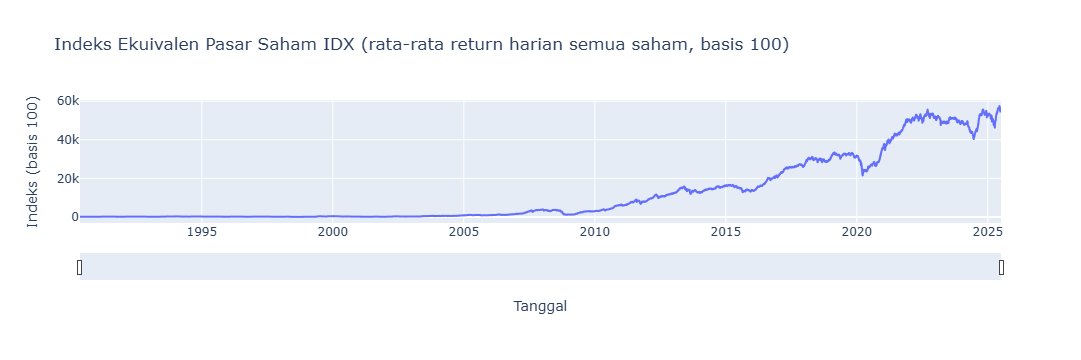

In [6]:
fig1 = px.line(
    indeks.to_pandas(), x="tanggal", y="indeks",
    title="Indeks Ekuivalen Pasar Saham IDX (rata-rata return harian semua saham, basis 100)",
    labels={"tanggal": "Tanggal", "indeks": "Indeks (basis 100)"},
)
fig1.update_xaxes(rangeslider_visible=True)
fig1.update_layout(hovermode="x unified")
# Kalau indeks tumbuh sangat besar, aktifkan skala log:
# fig1.update_yaxes(type="log")
fig1.show()

Sel 6 — distribusi return harian (histogram + box plot)

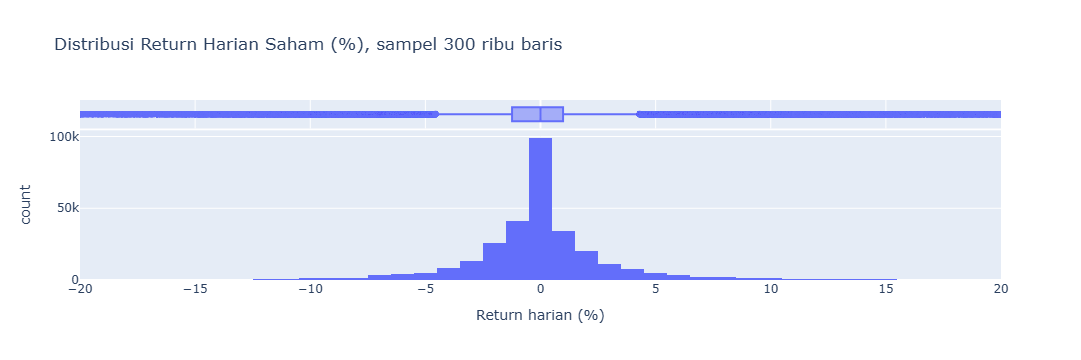

In [7]:
sampel = (
    df_ret.select((pl.col("ret") * 100).alias("ret_pct"))
    .sample(min(300_000, df_ret.height), seed=42)
)
fig2 = px.histogram(
    sampel.to_pandas(), x="ret_pct", nbins=150, marginal="box",
    range_x=[-20, 20],
    title="Distribusi Return Harian Saham (%), sampel 300 ribu baris",
    labels={"ret_pct": "Return harian (%)"},
)
fig2.show()

Sel 7 — korelasi return antar saham (heatmap, 20 saham dengan data terbanyak)

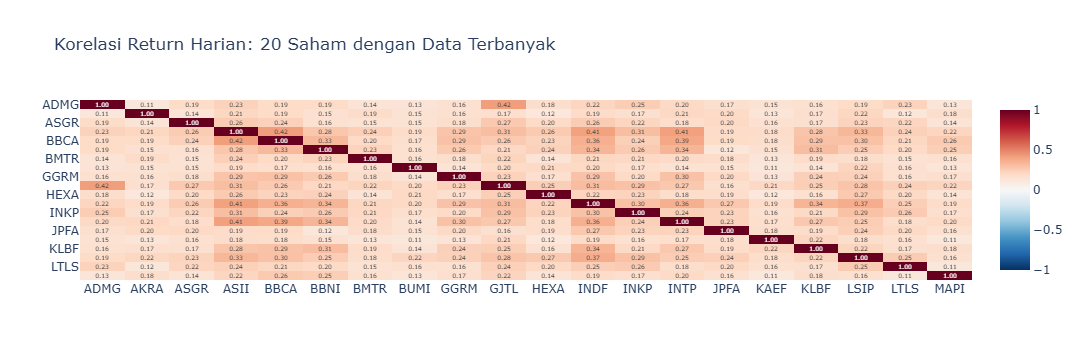

In [8]:
top20 = (
    df_ret.group_by("ticker").len()
    .sort("len", descending=True).head(20)["ticker"].to_list()
)
wide = (
    df_ret.filter(pl.col("ticker").is_in(top20))
    .pivot(on="ticker", index="tanggal", values="ret")
)
corr = wide.drop("tanggal").to_pandas().corr()

fig3 = px.imshow(
    corr, text_auto=".2f", zmin=-1, zmax=1, color_continuous_scale="RdBu_r",
    title="Korelasi Return Harian: 20 Saham dengan Data Terbanyak", aspect="auto",
)
fig3.show()

Sel 8 — komposisi volume per saham (treemap, 30 teratas)

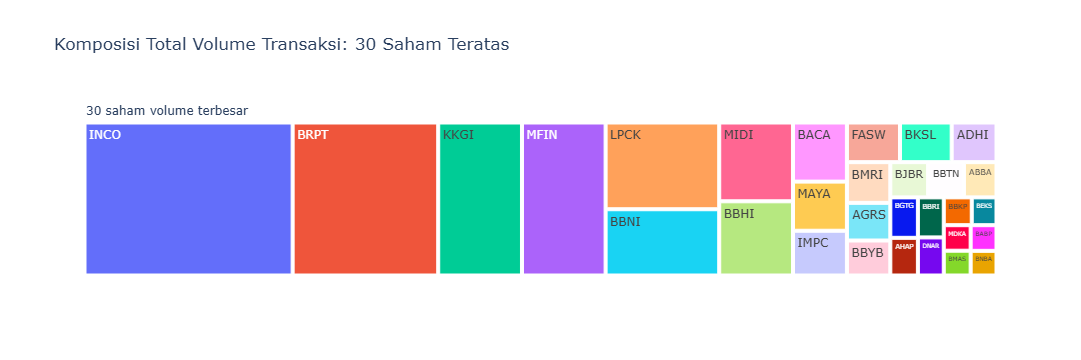

In [9]:
vol_ticker = (
    df.group_by("ticker").agg(pl.col("volume").sum().alias("total_volume"))
    .sort("total_volume", descending=True).head(30)
)
fig4 = px.treemap(
    vol_ticker.to_pandas(),
    path=[px.Constant("30 saham volume terbesar"), "ticker"],
    values="total_volume",
    title="Komposisi Total Volume Transaksi: 30 Saham Teratas",
)
fig4.show()

Sel 9 — pola musiman (heatmap rata-rata return per tahun x bulan)

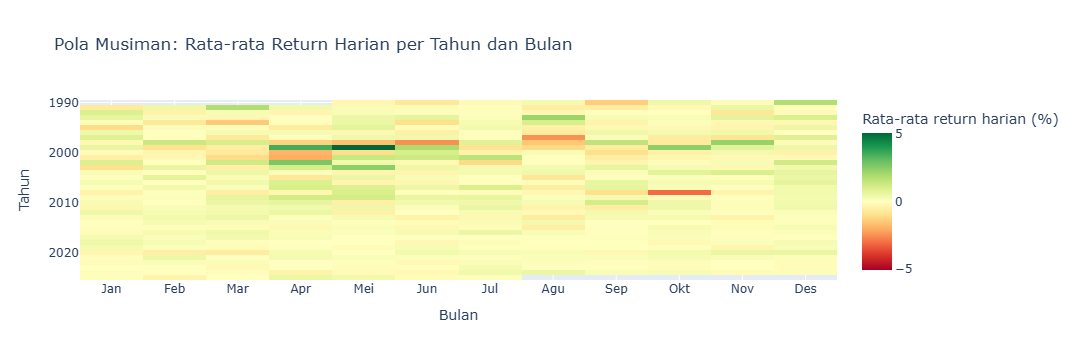

In [10]:
NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

musiman = (
    df_ret.group_by(["tahun", "bulan"])
    .agg((pl.col("ret").mean() * 100).alias("rata_ret_pct"))
)
pivot_musiman = musiman.pivot(on="bulan", index="tahun", values="rata_ret_pct").sort("tahun")
kolom_bulan = [m for m in range(1, 13) if str(m) in pivot_musiman.columns]

fig5 = px.imshow(
    pivot_musiman.select([str(m) for m in kolom_bulan]).to_numpy(),
    x=[NAMA_BULAN[m - 1] for m in kolom_bulan],
    y=pivot_musiman["tahun"].to_list(),
    color_continuous_scale="RdYlGn", color_continuous_midpoint=0, aspect="auto",
    labels={"x": "Bulan", "y": "Tahun", "color": "Rata-rata return harian (%)"},
    title="Pola Musiman: Rata-rata Return Harian per Tahun dan Bulan",
)
fig5.show()

Sel 10 — analisis multi-dimensi (risiko vs imbal hasil per saham)

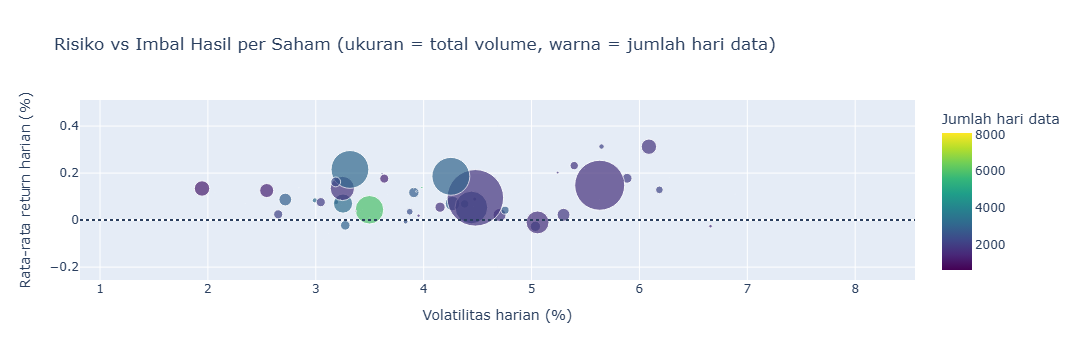

In [11]:
risiko = (
    df_ret.group_by("ticker")
    .agg(
        (pl.col("ret").mean() * 100).alias("rata_ret_pct"),
        (pl.col("ret").std() * 100).alias("volatilitas_pct"),
        pl.col("volume").sum().alias("total_volume"),
        pl.len().alias("n_hari"),
    )
    .filter(pl.col("n_hari") >= 250)
)
fig6 = px.scatter(
    risiko.to_pandas(), x="volatilitas_pct", y="rata_ret_pct",
    size="total_volume", color="n_hari", hover_name="ticker", size_max=40,
    color_continuous_scale="Viridis",
    title="Risiko vs Imbal Hasil per Saham (ukuran = total volume, warna = jumlah hari data)",
    labels={"volatilitas_pct": "Volatilitas harian (%)", "rata_ret_pct": "Rata-rata return harian (%)",
            "n_hari": "Jumlah hari data"},
)
fig6.add_hline(y=0, line_dash="dot")
fig6.show()

Sel 11 — Insight

In [12]:
NAMA_HARI = {1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu", 7: "Minggu"}

# Insight 1: tren
tahunan = (
    harian.with_columns(pl.col("tanggal").dt.year().alias("tahun"))
    .group_by("tahun")
    .agg((((1 + pl.col("ret_pasar")).product() - 1) * 100).alias("return_tahunan_pct"))
    .sort("tahun")
)
dd = indeks.with_columns(
    (pl.col("indeks") / pl.col("indeks").cum_max() - 1).alias("drawdown")
)
terbaik = tahunan.sort("return_tahunan_pct", descending=True).row(0, named=True)
terburuk = tahunan.sort("return_tahunan_pct").row(0, named=True)
print("[Insight 1] Tren")
print(f"  Indeks awal 100 -> akhir {indeks['indeks'][-1]:,.1f} ({indeks['tanggal'].min()} s/d {indeks['tanggal'].max()})")
print(f"  Tahun terbaik: {terbaik['tahun']} ({terbaik['return_tahunan_pct']:.1f}%), terburuk: {terburuk['tahun']} ({terburuk['return_tahunan_pct']:.1f}%)")
print(f"  Drawdown maksimum indeks: {dd['drawdown'].min() * 100:.1f}%")

# Insight 2: distribusi
r = df_ret["ret"]
print("\n[Insight 2] Distribusi return")
print(f"  Rata-rata {r.mean() * 100:.3f}%, std {r.std() * 100:.2f}%, kurtosis {r.kurtosis():.1f} (normal = 0)")
print(f"  Hari dengan |return| > 5%: {(r.abs() > 0.05).mean() * 100:.2f}%")
print(f"  Hari dengan return tepat 0 (tidak bergerak): {(r == 0).mean() * 100:.2f}%")

# Insight 3: korelasi
n = len(corr)
rata_korelasi = (corr.values.sum() - n) / (n * n - n)
print("\n[Insight 3] Korelasi")
print(f"  Rata-rata korelasi antar 20 saham teratas: {rata_korelasi:.2f}")

# Insight 4: konsentrasi dan musiman
total_vol = df["volume"].sum()
top5_share = vol_ticker.head(5)["total_volume"].sum() / total_vol * 100
bulan_rata = df_ret.group_by("bulan").agg((pl.col("ret").mean() * 100).alias("r")).sort("r")
hari_rata = df_ret.group_by("hari").agg((pl.col("ret").mean() * 100).alias("r")).sort("r")
print("\n[Insight 4] Segmen")
print(f"  5 saham teratas = {top5_share:.1f}% dari total volume seluruh data")
print(f"  Bulan terlemah: {NAMA_BULAN[bulan_rata['bulan'][0] - 1]} ({bulan_rata['r'][0]:.3f}%), terkuat: {NAMA_BULAN[bulan_rata['bulan'][-1] - 1]} ({bulan_rata['r'][-1]:.3f}%)")
print(f"  Hari terlemah: {NAMA_HARI[hari_rata['hari'][0]]} ({hari_rata['r'][0]:.3f}%), terkuat: {NAMA_HARI[hari_rata['hari'][-1]]} ({hari_rata['r'][-1]:.3f}%)")

# Insight 5: risiko vs imbal hasil
kor_rr = risiko.select(pl.corr("volatilitas_pct", "rata_ret_pct")).item()
print("\n[Insight 5] Risiko vs imbal hasil")
print(f"  Korelasi volatilitas vs rata-rata return antar saham: {kor_rr:.2f}")

[Insight 1] Tren
  Indeks awal 100 -> akhir 55,575.0 (1990-05-09 s/d 2025-07-04)
  Tahun terbaik: 1999 (626.8%), terburuk: 2008 (-67.9%)
  Drawdown maksimum indeks: -92.4%

[Insight 2] Distribusi return
  Rata-rata 0.085%, std 4.08%, kurtosis 18.6 (normal = 0)
  Hari dengan |return| > 5%: 11.41%
  Hari dengan return tepat 0 (tidak bergerak): 27.84%

[Insight 3] Korelasi
  Rata-rata korelasi antar 20 saham teratas: 0.21

[Insight 4] Segmen
  5 saham teratas = 63.3% dari total volume seluruh data
  Bulan terlemah: Agu (-0.004%), terkuat: Apr (0.191%)
  Hari terlemah: Senin (-0.047%), terkuat: Rabu (0.171%)

[Insight 5] Risiko vs imbal hasil
  Korelasi volatilitas vs rata-rata return antar saham: 0.49
